# 05 - Grid search on trees and ensemble learning (module 2, Lab 6 part II)

Week 3 extension of the baselines of `03_baseline.ipynb` (best: macro-F1 **0.477** on validation, 28 labels):

1. **Grid search on tree models** (decision tree, random forest), as in Lab 6 exercises 1 and 3, with a look at the bias–variance trade-off.
2. **Ensembles:** soft voting, bagging and stacking of the linear and tree models.
3. **Comparison** with the baseline: macro-F1 with bootstrap CI, paired bootstrap, inference time, model size, interpretability.
4. **Transformer in the vote:** the DistilBERT model of `06_transformer_training.ipynb` (module 3) combined with the classical models.

**Protocol (same as notebook 03):** fit and cross-validate on train only, tune per-label thresholds on validation (cross-fitted for the scores), never score the test set. Test and robustness-suite probabilities are only saved for module 4.

Runtime: about 10 minutes on a recent laptop (the grid searches and the stacking take most of it).

In [1]:
import os
import sys
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict
from sklearn.metrics import average_precision_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

sys.path.append(os.path.join("..", "src"))
from evaluation import *

SEED = 42
np.random.seed(SEED)

DATA_DIR = os.path.join("..", "data", "processed")
BASELINE_DIR = os.path.join("..", "results", "baselines")
OUT_DIR = os.path.join("..", "results", "ensembles")
os.makedirs(OUT_DIR, exist_ok = True)

## 1. Data

In [2]:
df_train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
df_val = pd.read_parquet(os.path.join(DATA_DIR, "validation.parquet"))
df_test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))
assert (len(df_train), len(df_val), len(df_test)) == (43188, 5377, 5379), "re-run 01_eda_simple.ipynb"

y_train = to_multi_hot(df_train["labels_28"], LABELS_28)
y_val = to_multi_hot(df_val["labels_28"], LABELS_28)
y_val_levels = {level: to_multi_hot(df_val[level], classes) for level, classes in LEVELS.items()}

# reference: the retained baseline of notebook 03 (AutoML v0.1 best)
proba_val_baseline = np.load(os.path.join(BASELINE_DIR, "proba_val_best.npy"))

# hand-written robustness suite of module 4 (32 messages): only predicted here, scored in 09_evaluation.ipynb
suite = pd.read_csv(os.path.join("..", "src", "robustness_suite.csv"))
print("Train:", len(df_train), "Validation:", len(df_val), "Test:", len(df_test), "Robustness suite:", len(suite))

Train: 43188 Validation: 5377 Test: 5379 Robustness suite: 32


## 2. Cross-validation folds for rare labels

Plain `KFold` splits at random, so a rare label can be unevenly spread between folds (one of the traps of Lab 6 exercise 1: no stratification).
For multi-label data, `MultilabelStratifiedKFold` (iterative stratification) keeps the share of every label close in each fold. We compare the number of examples of the rarest labels in each fold.

In [3]:
kfold = KFold(n_splits = 3, shuffle = True, random_state = SEED)
mskf = MultilabelStratifiedKFold(n_splits = 3, shuffle = True, random_state = SEED)

rows = []
for name, cv in [("KFold", kfold), ("MultilabelStratifiedKFold", mskf)]:
    for label in ["grief", "pride", "relief", "nervousness"]:
        j = LABELS_28.index(label)
        counts = [int(y_train[test_idx, j].sum()) for _, test_idx in cv.split(df_train, y_train)]
        rows.append({"folds": name, "label": label, "examples per fold": counts})
pd.DataFrame(rows)

,folds,label,examples per fold
0,KFold,grief,"[20, 29, 28]"
1,KFold,pride,"[34, 40, 37]"
2,KFold,relief,"[47, 53, 53]"
3,KFold,nervousness,"[52, 57, 55]"
4,MultilabelStratifiedKFold,grief,"[25, 26, 26]"
5,MultilabelStratifiedKFold,pride,"[37, 37, 37]"
6,MultilabelStratifiedKFold,relief,"[51, 51, 51]"
7,MultilabelStratifiedKFold,nervousness,"[55, 55, 54]"


From here on every cross-validation uses `MultilabelStratifiedKFold`. Its folds are fixed once (`CV_FOLDS`) so that all the grid searches and the stacking use exactly the same splits.

In [4]:
CV_FOLDS = list(mskf.split(df_train, y_train))

## 3. Grid search on tree models

Same TF-IDF features as the baseline (unigrams, punctuation and capitals kept). Decision trees and random forests handle the 28 labels natively (one tree predicts all labels), so no one-vs-rest wrapper is needed.

Scoring: **macro average precision** (threshold-free, every label counts the same), as in notebook 03, never accuracy.

In [5]:
TOKEN_PATTERN = r"(?u)\b\w+\b|[^\w\s]"

def make_vectorizer(ngram_range = (1, 1)):
    return TfidfVectorizer(lowercase = False, token_pattern = TOKEN_PATTERN,
                           ngram_range = ngram_range, min_df = 2, sublinear_tf = True)


def proba_matrix(model, X):
    # trees and forests return one (n, 2) array per label: keep the probability of class 1
    proba = model.predict_proba(X)
    if isinstance(proba, list):
        proba = np.column_stack([p[:, 1] for p in proba])
    return proba


def macro_ap_scorer(estimator, X, y):
    return average_precision_score(y, proba_matrix(estimator, X), average = "macro")

### 3.1. Decision tree, and the bias–variance trade-off

In [6]:
pipe_tree = Pipeline([
    ("tfidf", make_vectorizer()),
    ("clf", DecisionTreeClassifier(random_state = SEED)),
])
grid_tree = {
    "clf__max_depth": [10, 50, None],
    "clf__min_samples_leaf": [1, 5, 20],
}
search_tree = GridSearchCV(pipe_tree, grid_tree, scoring = macro_ap_scorer, cv = CV_FOLDS,
                           return_train_score = True, n_jobs = -1, refit = True)

start = time.time()
search_tree.fit(df_train["text"], y_train)
print("Search time:", round((time.time() - start) / 60, 1), "min")
print("Best setting:", search_tree.best_params_, "| CV macro average precision:", round(search_tree.best_score_, 3))

Search time: 2.3 min
Best setting: {'clf__max_depth': None, 'clf__min_samples_leaf': 20} | CV macro average precision: 0.237


In [7]:
tree_results = pd.DataFrame(search_tree.cv_results_)[["param_clf__max_depth", "param_clf__min_samples_leaf",
                                                       "mean_train_score", "mean_test_score"]]
tree_results.columns = ["max_depth", "min_samples_leaf", "train AP", "CV AP"]
tree_results["gap (overfitting)"] = tree_results["train AP"] - tree_results["CV AP"]
tree_results.round(3).sort_values("CV AP", ascending = False)

,max_depth,min_samples_leaf,train AP,CV AP,gap (overfitting)
8,None,20,0.352,0.237,0.116
5,50,20,0.297,0.228,0.069
7,None,5,0.570,0.219,0.351
4,50,5,0.382,0.205,0.178
3,50,1,0.513,0.165,0.348
6,None,1,1.000,0.143,0.857
1,10,5,0.139,0.129,0.010
2,10,20,0.139,0.129,0.010
0,10,1,0.144,0.127,0.017


**Bias–variance (Lab 6 exercise 1 questions).** With `max_depth = None` and `min_samples_leaf = 1` the tree almost memorises train (train AP close to 1) but generalises badly: high variance, overfitting. Larger leaves or a smaller depth lower the train score but shrink the gap: more bias, less variance. The best CV score sits in between.

### 3.2. Random forest (bagging of trees)

A random forest averages many trees trained on bootstrap samples with random feature subsets, which reduces the variance of a single tree.
`min_samples_leaf = 1` is left out on purpose: on 15,000 sparse features, fully grown trees for 28 labels take several GB of memory (it crashed a 7 GB machine) for a worse score.

In [8]:
pipe_rf = Pipeline([
    ("tfidf", make_vectorizer()),
    ("clf", RandomForestClassifier(n_estimators = 100, max_features = "sqrt", n_jobs = -1, random_state = SEED)),
])
grid_rf = {"clf__min_samples_leaf": [3, 5, 10]}
search_rf = GridSearchCV(pipe_rf, grid_rf, scoring = macro_ap_scorer, cv = CV_FOLDS,
                         return_train_score = True, n_jobs = 1, refit = True)

start = time.time()
search_rf.fit(df_train["text"], y_train)
print("Search time:", round((time.time() - start) / 60, 1), "min")
print("Best setting:", search_rf.best_params_, "| CV macro average precision:", round(search_rf.best_score_, 3))
pd.DataFrame(search_rf.cv_results_)[["param_clf__min_samples_leaf", "mean_train_score", "mean_test_score"]].round(3)

Search time: 2.2 min
Best setting: {'clf__min_samples_leaf': 3} | CV macro average precision: 0.37


,param_clf__min_samples_leaf,mean_train_score,mean_test_score
0,3,0.733,0.370
1,5,0.598,0.364
2,10,0.481,0.355


## 4. Base models for the ensembles

Four models that make different kinds of errors, all fitted on train:

| Model | Features | Classifier |
|---|---|---|
| `logreg_word` | word unigrams | logistic regression, C = 4 (AutoML v0.1 best of notebook 03) |
| `logreg_char` | character 2–5-grams | logistic regression, C = 4, balanced |
| `svm_word` | word 1–2-grams | linear SVM, C = 0.5, balanced, calibrated (Platt) |
| `forest` | word unigrams | random forest, best setting of section 3.2 |

In [9]:
def make_logreg_word():
    return Pipeline([("tfidf", make_vectorizer((1, 1))),
                     ("clf", OneVsRestClassifier(LogisticRegression(C = 4, solver = "liblinear", max_iter = 1000)))])

def make_logreg_char():
    return Pipeline([("tfidf", TfidfVectorizer(analyzer = "char_wb", ngram_range = (2, 5), min_df = 3,
                                               sublinear_tf = True, lowercase = False)),
                     ("clf", OneVsRestClassifier(LogisticRegression(C = 4, class_weight = "balanced",
                                                                    solver = "liblinear", max_iter = 1000)))])

def make_svm_word():
    return Pipeline([("tfidf", make_vectorizer((1, 2))),
                     ("clf", OneVsRestClassifier(CalibratedClassifierCV(LinearSVC(C = 0.5, class_weight = "balanced"), cv = 3)))])

def make_forest():
    return Pipeline([("tfidf", make_vectorizer((1, 1))),
                     ("clf", RandomForestClassifier(n_estimators = 100, max_features = "sqrt", n_jobs = -1, random_state = SEED,
                                                    min_samples_leaf = search_rf.best_params_["clf__min_samples_leaf"]))])

base_makers = {"logreg_word": make_logreg_word, "logreg_char": make_logreg_char,
               "svm_word": make_svm_word, "forest": make_forest}

base_models = {}
proba_val = {}
proba_test = {}
proba_suite = {}
fit_time = {}
for name, maker in base_makers.items():
    start = time.time()
    model = maker().fit(df_train["text"], y_train)
    fit_time[name] = time.time() - start
    base_models[name] = model
    proba_val[name] = proba_matrix(model, df_val["text"])
    proba_test[name] = proba_matrix(model, df_test["text"])
    proba_suite[name] = proba_matrix(model, suite["text"])
    print(name, "- training time:", round(fit_time[name], 1), "s")

proba_val["decision_tree"] = proba_matrix(search_tree.best_estimator_, df_val["text"])
proba_test["decision_tree"] = proba_matrix(search_tree.best_estimator_, df_test["text"])

logreg_word - training time: 4.6 s


logreg_char - training time: 119.0 s


svm_word - training time: 31.8 s


forest - training time: 22.0 s


## 5. Ensembles

### 5.1. Soft voting

Average of the probabilities of the four base models, then per-label thresholds as for every model.
scikit-learn's `VotingClassifier` does not accept a multi-label target directly; averaging the `predict_proba` outputs ourselves is exactly what `voting = "soft"` does, without refitting the models.

In [10]:
members = ["logreg_word", "logreg_char", "svm_word", "forest"]
proba_val["voting_soft"] = np.mean([proba_val[m] for m in members], axis = 0)
proba_test["voting_soft"] = np.mean([proba_test[m] for m in members], axis = 0)
proba_suite["voting_soft"] = np.mean([proba_suite[m] for m in members], axis = 0)

# a smaller vote without the forest, to see what the tree model brings
members_linear = ["logreg_word", "logreg_char", "svm_word"]
proba_val["voting_linear"] = np.mean([proba_val[m] for m in members_linear], axis = 0)
proba_test["voting_linear"] = np.mean([proba_test[m] for m in members_linear], axis = 0)

### 5.2. Bagging of the logistic regression

`BaggingClassifier` trains several logistic regressions on random subsets of train and averages them (the Lab's "Bagging SVM", with our main linear model). Its parameters (`max_samples`) are chosen by grid search on train.
Expectation: bagging reduces **variance**; a regularised linear model has little variance, so the gain should be small, unlike the trees.

In [11]:
pipe_bag = Pipeline([
    ("tfidf", make_vectorizer((1, 1))),
    ("clf", OneVsRestClassifier(BaggingClassifier(LogisticRegression(C = 4, solver = "liblinear", max_iter = 1000),
                                                  n_estimators = 10, random_state = SEED))),
])
grid_bag = {"clf__estimator__max_samples": [0.5, 0.8]}
search_bag = GridSearchCV(pipe_bag, grid_bag, scoring = macro_ap_scorer, cv = CV_FOLDS, n_jobs = -1, refit = True)

start = time.time()
search_bag.fit(df_train["text"], y_train)
fit_time["bagging_logreg"] = time.time() - start
print("Search time:", round(fit_time["bagging_logreg"] / 60, 1), "min")
print("Best setting:", search_bag.best_params_, "| CV macro average precision:", round(search_bag.best_score_, 3))

proba_val["bagging_logreg"] = proba_matrix(search_bag.best_estimator_, df_val["text"])
proba_test["bagging_logreg"] = proba_matrix(search_bag.best_estimator_, df_test["text"])

Search time: 1.5 min
Best setting: {'clf__estimator__max_samples': 0.8} | CV macro average precision: 0.391


### 5.3. Stacking

A meta-model learns how to combine the base models. For each label, a logistic regression takes the **28 × 4 = 112 probabilities** of the four base models, so it can use the other labels too (for example "annoyance" helps to predict "anger").

**Leakage trap:** the meta-model must not be trained on predictions the base models made on their own training data (they would look too good). We use **out-of-fold** predictions on train: each comment is predicted by base models trained on the other two folds (`cross_val_predict`, same stratified folds). The base models refitted on the whole train set (section 4) then feed the meta-model on validation and test.

In [12]:
start = time.time()
oof_train = {}
for name in members:
    oof_train[name] = cross_val_predict(base_makers[name](), df_train["text"], y_train,
                                        cv = CV_FOLDS, method = "predict_proba")
    if isinstance(oof_train[name], list):
        oof_train[name] = np.column_stack([p[:, 1] for p in oof_train[name]])
    print(name, "out-of-fold done")
print("Out-of-fold time:", round((time.time() - start) / 60, 1), "min")

X_meta_train = np.hstack([oof_train[m] for m in members])
X_meta_val = np.hstack([proba_val[m] for m in members])
X_meta_test = np.hstack([proba_test[m] for m in members])
print("Meta features:", X_meta_train.shape)

logreg_word out-of-fold done


logreg_char out-of-fold done


svm_word out-of-fold done


forest out-of-fold done
Out-of-fold time: 5.2 min
Meta features: (43188, 112)


In [13]:
meta_model = OneVsRestClassifier(LogisticRegression(C = 1, max_iter = 1000))
start = time.time()
meta_model.fit(X_meta_train, y_train)
fit_time["stacking"] = time.time() - start + sum(fit_time[m] for m in members)

proba_val["stacking"] = meta_model.predict_proba(X_meta_val)
proba_test["stacking"] = meta_model.predict_proba(X_meta_test)

## 6. Comparison on validation (28 labels)

Same rule for every model: per-label thresholds, cross-fitted on validation (two halves: tune on one, score the other), and bootstrap 95% CI.
Each model is compared with the retained baseline of notebook 03 with a **paired bootstrap** on the same comments.

In [14]:
def crossfit_predict(y_true, proba, seed = SEED):
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(y_true))
    half_a, half_b = order[: len(order) // 2], order[len(order) // 2 :]
    y_pred = np.zeros_like(y_true)
    for tune_idx, apply_idx in [(half_a, half_b), (half_b, half_a)]:
        thresholds_half = tune_thresholds(y_true[tune_idx], proba[tune_idx])
        y_pred[apply_idx] = apply_thresholds(proba[apply_idx], thresholds_half)
    return y_pred

y_pred_baseline = crossfit_predict(y_val, proba_val_baseline)

model_order = ["decision_tree", "forest", "logreg_word", "logreg_char", "svm_word",
               "bagging_logreg", "voting_linear", "voting_soft", "stacking"]
y_pred_val = {}
rows = []
for name in model_order:
    y_pred_val[name] = crossfit_predict(y_val, proba_val[name])
    row = evaluate(name, y_val, y_pred_val[name])
    paired = paired_bootstrap(y_val, y_pred_baseline, y_pred_val[name])
    row["gain_vs_baseline"] = paired["diff_b_minus_a"]
    row["gain_ci"] = "[" + str(round(paired["ci_low"], 3)) + ", " + str(round(paired["ci_high"], 3)) + "]"
    rows.append(row)

results_val = pd.DataFrame(rows)
results_val.to_csv(os.path.join(OUT_DIR, "validation_results_28.csv"), index = False)
format_results(results_val)[["model", "macro_f1", "micro_f1", "gain_vs_baseline", "gain_ci"]]

,model,macro_f1,micro_f1,gain_vs_baseline,gain_ci
0,decision_tree,"0.337 [0.321, 0.353]","0.420 [0.411, 0.430]",-0.140,"[-0.159, -0.12]"
1,forest,"0.447 [0.426, 0.464]","0.519 [0.508, 0.529]",-0.030,"[-0.048, -0.013]"
2,logreg_word,"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]",0.000,"[0.0, 0.0]"
3,logreg_char,"0.468 [0.449, 0.485]","0.523 [0.514, 0.532]",-0.009,"[-0.023, 0.005]"
4,svm_word,"0.465 [0.446, 0.481]","0.528 [0.518, 0.538]",-0.012,"[-0.027, 0.003]"
5,bagging_logreg,"0.476 [0.454, 0.494]","0.526 [0.516, 0.535]",-0.001,"[-0.011, 0.009]"
6,voting_linear,"0.488 [0.468, 0.506]","0.546 [0.536, 0.556]",0.011,"[-0.0, 0.022]"
7,voting_soft,"0.495 [0.474, 0.512]","0.550 [0.540, 0.559]",0.018,"[0.007, 0.028]"
8,stacking,"0.484 [0.463, 0.501]","0.544 [0.534, 0.553]",0.006,"[-0.009, 0.021]"


### 6.1. Cost and interpretability (Lab 6 exercise 3, table)

Inference time: predicting the 5,377 validation comments, reported per 1,000 comments. Model size: the pickled model on disk.

In [15]:
def model_size_mb(model):
    return len(pickle.dumps(model)) / 1e6

def inference_ms_per_1000(predict):
    start = time.time()
    predict(df_val["text"])
    return 1000 * (time.time() - start) / len(df_val) * 1000

costs = {}
for name in members:
    costs[name] = (inference_ms_per_1000(lambda X, m = base_models[name]: proba_matrix(m, X)), model_size_mb(base_models[name]))
costs["decision_tree"] = (inference_ms_per_1000(lambda X: proba_matrix(search_tree.best_estimator_, X)), model_size_mb(search_tree.best_estimator_))
costs["bagging_logreg"] = (inference_ms_per_1000(lambda X: proba_matrix(search_bag.best_estimator_, X)), model_size_mb(search_bag.best_estimator_))
costs["voting_linear"] = tuple(np.sum([costs[m] for m in members_linear], axis = 0))
costs["voting_soft"] = tuple(np.sum([costs[m] for m in members], axis = 0))
costs["stacking"] = (costs["voting_soft"][0], costs["voting_soft"][1] + model_size_mb(meta_model))

interpretability = {
    "decision_tree": "High: one tree, rules can be read (but very deep)",
    "forest": "Low: 100 trees; only global feature importances",
    "logreg_word": "High: one weight per word and label",
    "logreg_char": "Medium: weights on character pieces",
    "svm_word": "Medium: linear weights, but calibrated scores",
    "bagging_logreg": "Medium: average of 10 linear models",
    "voting_linear": "Medium: average of 3 linear models",
    "voting_soft": "Low: linear models + forest",
    "stacking": "Low: two levels of models",
}

cost_table = pd.DataFrame({
    "model": model_order,
    "macro_F1": [results_val.set_index("model").loc[m, "macro_f1"] for m in model_order],
    "inference_ms_per_1000": [costs[m][0] for m in model_order],
    "size_MB": [costs[m][1] for m in model_order],
    "interpretability": [interpretability[m] for m in model_order],
}).round(3)
cost_table.to_csv(os.path.join(OUT_DIR, "cost_table.csv"), index = False)
cost_table

,model,macro_F1,inference_ms_per_1000,size_MB,interpretability
0,decision_tree,0.337,10.297,2.027,"High: one tree, rules can be read (but very deep)"
1,forest,0.447,49.350,120.281,Low: 100 trees; only global feature importances
2,logreg_word,0.477,12.116,3.742,High: one weight per word and label
3,logreg_char,0.468,102.106,18.761,Medium: weights on character pieces
4,svm_word,0.465,38.437,48.169,"Medium: linear weights, but calibrated scores"
5,bagging_logreg,0.476,61.786,68.819,Medium: average of 10 linear models
6,voting_linear,0.488,152.660,70.672,Medium: average of 3 linear models
7,voting_soft,0.495,202.010,190.953,Low: linear models + forest
8,stacking,0.484,202.010,190.986,Low: two levels of models


### 6.2. Figure for the report

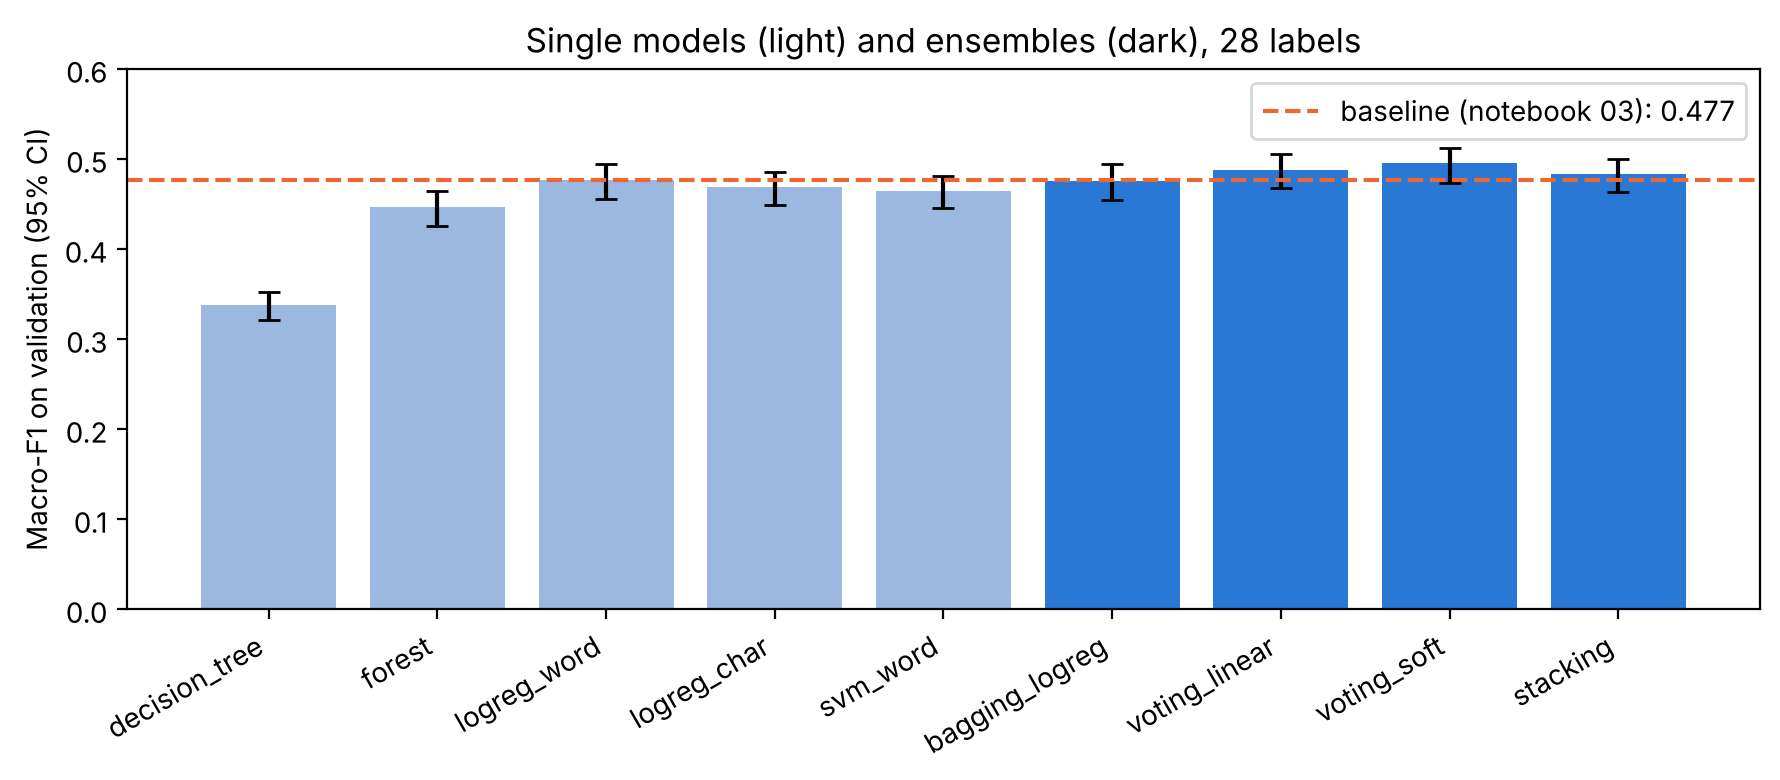

In [16]:
plot_df = results_val.set_index("model").loc[model_order]
errors = np.vstack([plot_df["macro_f1"] - plot_df["macro_f1_low"], plot_df["macro_f1_high"] - plot_df["macro_f1"]])
colors = ["#2a78d6" if m in ["voting_soft", "voting_linear", "stacking", "bagging_logreg"] else "#9bb8e0" for m in model_order]

fig, ax = plt.subplots(figsize = (9, 4))
ax.bar(model_order, plot_df["macro_f1"], yerr = errors, capsize = 4, color = colors)
ax.axhline(0.477, color = "#eb6834", linestyle = "--", label = "baseline (notebook 03): 0.477")
ax.set_ylabel("Macro-F1 on validation (95% CI)")
ax.set_title("Single models (light) and ensembles (dark), 28 labels")
ax.set_ylim(0, 0.6)
ax.legend()
plt.xticks(rotation = 30, ha = "right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "macro_f1_comparison.png"))
plt.show()

## 7. Best ensemble at the three label levels

In [17]:
best_name = results_val.set_index("model").loc[["bagging_logreg", "voting_linear", "voting_soft", "stacking"], "macro_f1"].idxmax()
print("Best ensemble on validation:", best_name)

results_levels = pd.concat([evaluate_all_levels("baseline (03)", y_pred_baseline, y_val_levels),
                            evaluate_all_levels(best_name, y_pred_val[best_name], y_val_levels)], ignore_index = True)
results_levels.to_csv(os.path.join(OUT_DIR, "validation_results_levels.csv"), index = False)
format_results(results_levels)[["model", "level", "macro_f1", "micro_f1"]]

Best ensemble on validation: voting_soft


,model,level,macro_f1,micro_f1
0,baseline (03),28,"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]"
1,baseline (03),ekman,"0.546 [0.527, 0.564]","0.620 [0.611, 0.630]"
2,baseline (03),sentiment,"0.615 [0.604, 0.625]","0.646 [0.636, 0.655]"
3,voting_soft,28,"0.495 [0.474, 0.512]","0.550 [0.540, 0.559]"
4,voting_soft,ekman,"0.569 [0.551, 0.587]","0.643 [0.634, 0.652]"
5,voting_soft,sentiment,"0.641 [0.630, 0.653]","0.668 [0.659, 0.677]"


In [18]:
# per-label gain of the best ensemble over the baseline
report_base = per_class_report(y_val, y_pred_baseline, LABELS_28)
report_best = per_class_report(y_val, y_pred_val[best_name], LABELS_28)
per_label = pd.DataFrame({"baseline_f1": report_base["f1"], "ensemble_f1": report_best["f1"], "support": report_base["support"]})
per_label["gain"] = per_label["ensemble_f1"] - per_label["baseline_f1"]
per_label.to_csv(os.path.join(OUT_DIR, "per_class_gain.csv"))
per_label.sort_values("gain").round(3)

,baseline_f1,ensemble_f1,support,gain
grief,0.560,0.500,13,-0.060
optimism,0.570,0.562,209,-0.008
remorse,0.722,0.719,68,-0.003
embarrassment,0.557,0.557,35,0.000
nervousness,0.378,0.378,21,0.000
relief,0.214,0.214,18,0.000
joy,0.565,0.566,170,0.001
gratitude,0.907,0.908,343,0.001
love,0.765,0.767,244,0.002
approval,0.290,0.293,394,0.003


## 8. Adding the transformer to the vote

The transformer of `06_transformer_training.ipynb` (average of 3 DistilBERT seeds, macro-F1 0.524 on validation) reads the words in context, the classical models count words and character pieces: they should make different errors. We average probabilities, as in section 5.1, without new training:

- **Transformer + soft vote:** half transformer, half the 4-model classical vote.
- **Transformer + logistic regression:** half transformer, half the baseline, the cheapest combination.

Both are compared with the transformer alone with the paired bootstrap.

In [19]:
TRANSFORMER_DIR = os.path.join("..", "results", "transformer")
proba_val["transformer"] = np.load(os.path.join(TRANSFORMER_DIR, "proba_val_transformer.npy"))
proba_test["transformer"] = np.load(os.path.join(TRANSFORMER_DIR, "proba_test_transformer.npy"))
proba_suite["transformer"] = np.load(os.path.join(TRANSFORMER_DIR, "proba_suite_transformer.npy"))
assert proba_val["transformer"].shape == (len(df_val), 28) and proba_suite["transformer"].shape == (len(suite), 28)

for split_proba in [proba_val, proba_test, proba_suite]:
    split_proba["transformer_vote"] = (split_proba["transformer"] + split_proba["voting_soft"]) / 2
    split_proba["transformer_logreg"] = (split_proba["transformer"] + split_proba["logreg_word"]) / 2

y_pred_transformer = crossfit_predict(y_val, proba_val["transformer"])
rows = []
for name in ["transformer", "transformer_logreg", "transformer_vote"]:
    y_pred_val[name] = crossfit_predict(y_val, proba_val[name])
    row = evaluate(name, y_val, y_pred_val[name])
    vs_baseline = paired_bootstrap(y_val, y_pred_baseline, y_pred_val[name])
    vs_transformer = paired_bootstrap(y_val, y_pred_transformer, y_pred_val[name])
    row["gain_vs_baseline"] = vs_baseline["diff_b_minus_a"]
    row["gain_vs_transformer"] = vs_transformer["diff_b_minus_a"]
    row["gain_vs_transformer_ci"] = "[" + str(round(vs_transformer["ci_low"], 3)) + ", " + str(round(vs_transformer["ci_high"], 3)) + "]"
    rows.append(row)

results_transformer = pd.DataFrame(rows)
results_transformer.to_csv(os.path.join(OUT_DIR, "validation_results_transformer_vote.csv"), index = False)
format_results(results_transformer)[["model", "macro_f1", "micro_f1", "gain_vs_baseline", "gain_vs_transformer", "gain_vs_transformer_ci"]]

,model,macro_f1,micro_f1,gain_vs_baseline,gain_vs_transformer,gain_vs_transformer_ci
0,transformer,"0.524 [0.503, 0.541]","0.589 [0.579, 0.599]",0.047,0.000,"[0.0, 0.0]"
1,transformer_logreg,"0.538 [0.518, 0.555]","0.597 [0.587, 0.607]",0.061,0.014,"[0.002, 0.028]"
2,transformer_vote,"0.536 [0.515, 0.553]","0.598 [0.588, 0.607]",0.059,0.012,"[-0.001, 0.027]"


In [20]:
results_levels_tr = pd.concat([evaluate_all_levels(name, y_pred_val[name], y_val_levels)
                               for name in ["transformer", "transformer_vote"]], ignore_index = True)
results_levels_tr.to_csv(os.path.join(OUT_DIR, "validation_results_levels_transformer_vote.csv"), index = False)
format_results(results_levels_tr)[["model", "level", "macro_f1", "micro_f1"]]

,model,level,macro_f1,micro_f1
0,transformer,28,"0.524 [0.503, 0.541]","0.589 [0.579, 0.599]"
1,transformer,ekman,"0.616 [0.597, 0.635]","0.695 [0.686, 0.705]"
2,transformer,sentiment,"0.691 [0.680, 0.704]","0.721 [0.712, 0.730]"
3,transformer_vote,28,"0.536 [0.515, 0.553]","0.598 [0.588, 0.607]"
4,transformer_vote,ekman,"0.621 [0.602, 0.638]","0.697 [0.687, 0.706]"
5,transformer_vote,sentiment,"0.693 [0.683, 0.704]","0.722 [0.712, 0.731]"


## 9. Save probabilities and thresholds for module 4

Same format as notebook 03: `.npy`, shape `(n, 28)`, columns in `LABELS_28` order, rows in the order of `data/processed/*.parquet`. The thresholds are tuned on the whole validation set. The robustness-suite probabilities (`proba_suite_*.npy`, rows in the order of `src/robustness_suite.csv`) are saved for `09_evaluation.ipynb`. No test score is computed here.

In [21]:
for name in ["voting_soft", "stacking", "bagging_logreg", "forest", "transformer_vote", "transformer_logreg"]:
    np.save(os.path.join(OUT_DIR, "proba_val_" + name + ".npy"), proba_val[name].astype(np.float32))
    np.save(os.path.join(OUT_DIR, "proba_test_" + name + ".npy"), proba_test[name].astype(np.float32))
    np.save(os.path.join(OUT_DIR, "thresholds_" + name + ".npy"), tune_thresholds(y_val, proba_val[name]))

# robustness suite: the baseline (refitted here with the same setting) and the votes
for name in ["logreg_word", "voting_soft", "transformer_vote", "transformer_logreg"]:
    np.save(os.path.join(OUT_DIR, "proba_suite_" + name + ".npy"), proba_suite[name].astype(np.float32))

# the refitted logistic regression is the baseline of notebook 03: same probabilities on validation
print("logreg_word equals the baseline of notebook 03:", np.allclose(proba_val["logreg_word"], proba_val_baseline, atol = 1e-5))
print("Saved in", OUT_DIR)

logreg_word equals the baseline of notebook 03: True
Saved in ../results/ensembles


## 10. Summary (validation set, 28 labels)

| Model | Macro-F1 [95% CI] | Gain vs baseline [95% CI] | Inference (ms / 1,000 comments) | Size (MB) |
|---|---|---|---|---|
| Decision tree (best grid) | 0.337 [0.321, 0.353] | −0.140 [−0.159, −0.120] | 10 | 2 |
| Random forest (best grid) | 0.447 [0.426, 0.464] | −0.030 [−0.048, −0.013] | 49 | 120 |
| **Baseline: logistic regression, word unigrams** | **0.477 [0.456, 0.495]** | – | 12 | 4 |
| Logistic regression, character n-grams | 0.468 [0.449, 0.485] | −0.009 [−0.023, 0.005] | 102 | 19 |
| Linear SVM, word 1–2-grams | 0.465 [0.446, 0.481] | −0.012 [−0.027, 0.003] | 38 | 48 |
| Bagging of logistic regressions | 0.476 [0.454, 0.494] | −0.001 [−0.011, 0.009] | 62 | 69 |
| Soft voting, 3 linear models | 0.488 [0.468, 0.506] | +0.011 [0.000, 0.022] | 153 | 71 |
| **Soft voting, 3 linear models + forest** | **0.495 [0.474, 0.512]** | **+0.018 [0.007, 0.028]** | 202 | 191 |
| Stacking (meta logistic regression) | 0.484 [0.463, 0.501] | +0.006 [−0.009, 0.021] | 202 | 191 |
| Transformer (notebook 06) | 0.524 [0.503, 0.541] | +0.047 | – | – |
| **Transformer + baseline (section 8)** | **0.538 [0.518, 0.555]** | **+0.061** | – | – |
| Transformer + soft vote (section 8) | 0.536 [0.515, 0.553] | +0.059 | – | – |

Inference times were measured on a 2-core machine: compare them with each other, not as absolute values.

**Findings**
- **Grid search on trees and bias–variance:** a fully grown decision tree (`max_depth = None`, `min_samples_leaf = 1`) reaches a train AP of 1.00 but only 0.14 in cross-validation (gap 0.86): it memorises train. Larger leaves trade variance for bias; the best tree (leaves of 20) is still far below the linear models (0.337), because one tree splits on one word at a time and the TF-IDF space is sparse (15,000 features).
- **Bagging works where there is variance:** averaging 100 trees (random forest) raises a tree from 0.337 to 0.447, but bagging the logistic regression changes nothing (−0.001): a regularised linear model has low variance, so there is little to average out.
- **Among classical models, soft voting is the best** and the only one significantly better than the baseline: +0.018 macro-F1, paired bootstrap 95% CI [0.007, 0.028]. The forest is weaker alone but useful in the vote (0.488 without it, 0.495 with it), because it makes different errors from the linear models. The largest gains are on hard, mid-frequency emotions (excitement +0.08, sadness, realization, disappointment +0.05).
- **Stacking does not beat simple voting** (+0.006, not significant): learning 28 × 112 meta-weights adds variance, and simple averaging is already a strong combination.
- **The transformer and the baseline complement each other:** averaging the transformer with the plain logistic regression gives the best model of the project, 0.538, significantly better than the transformer alone (+0.014, 95% CI [0.002, 0.028]). Adding the whole soft vote instead brings nothing more (0.536, not significant): once the transformer is there, one linear model is enough to bring the word-count view.
- **Cost:** the classical vote is 15 times slower and 50 times larger than the baseline for +0.018. The transformer + baseline combination costs only 4 MB and a few milliseconds on top of the transformer, so it is the best trade-off for the final model.